# Fast extragradient: convergence discovery
Let $A$ be a monotone, $L$-Lipschitz operator on a finite-dimensional real Euclidean space, with $L>0$, $A(x_\star)=0$, and $\|x_0-x_\star\|^2\le R^2$, $R\ge0$.
For $k=0,\ldots,N-1$, use
$$x_{k+1/2}=x_k+\frac{x_0-x_k}{k+1}-\frac{k}{(k+1)L}A(x_k),$$
$$x_{k+1}=x_k+\frac{x_0-x_k}{k+1}-\frac1L A(x_{k+1/2}).$$
The first intermediate point is exactly $x_{1/2}=x_0$. The target is $\|A(x_N)\|^2$ for integer $N\ge1$.

## Proof Statement

### Theorem
Under the assumptions and updates above, for every integer $N\ge1$,
$$\boxed{\|A(x_{N})\|^2\le\frac{4L^2R^2}{N^2}.}$$
A nonincreasing Lyapunov certificate is
$$\boxed{V_{0}=0,\qquad V_{k}=k^2\|A(x_{k})\|^2+2kL\langle A(x_{k}),x_{k}-x_{0}\rangle\quad(1\le k\le N).}$$
The potential need not be nonnegative; the terminal square identity below converts $V_{N}\le0$ into the residual bound. This exact potential is a positive rescaling of the structure discovered numerically. No matching closed-form formula for the particular floating-point full-PEP dual is claimed.

### Proof outline
Write $g_{k}=A(x_{k})$ and define the nonpositive residuals
$$\operatorname{Lip}(u,v)=\|A(u)-A(v)\|^2-L^2\|u-v\|^2,\qquad
\operatorname{Mon}(u,v)=-\langle A(u)-A(v),u-v\rangle.$$
For $V_{k}=k^2\|g_{k}\|^2+2kL\langle g_{k},x_{k}-x_{0}\rangle$, the shared point $x_{1/2}=x_{0}$ and $x_{1}=x_{0}-g_{0}/L$ give
$$V_{1}-V_{0}=\operatorname{Lip}(x_{0},x_{1})\le0.$$
For $1\le k<N$, substitution of both updates gives the exact identity
$$V_{k+1}-V_{k}=(k+1)^2\operatorname{Lip}(x_{k+1/2},x_{k+1})+2k(k+1)L\operatorname{Mon}(x_{k},x_{k+1})\le0.$$
The multipliers are nonnegative because $L>0$ and $k\ge1$. Thus $V_{N}\le V_{1}\le0$.
Let $d=x_{0}-x_{\star}$ and use $A(x_{\star})=0$. The terminal identity is
$$N^2\|g_{N}\|^2-4L^2\|d\|^2
=2V_{N}+4NL\operatorname{Mon}(x_{N},x_{\star})-\|Ng_{N}-2Ld\|^2\le0.$$
Both additional terms on the right are nonpositive. Consequently
$$\|g_{N}\|^2\le\frac{4L^2\|d\|^2}{N^2}\le\frac{4L^2R^2}{N^2}.$$
For $N=1$ the recursion range is empty and the base and terminal identities suffice. The proof never divides by $R$, so it also covers $R=0$.

In [1]:
from pathlib import Path
import sys

notebook_dir = Path(
    "C:\\Users\\Jack\\Documents\\GitHub\\PEPFlow\\examples_peppy\\_evaluations\\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\\feg\\r05"
)
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [
    str(repo_root),
    str(notebook_dir),
    str(notebook_dir / "supplementary" / "helpers"),
]

In [2]:
from pathlib import Path
import sys
import json
import pepflow as pf
import sympy as sp
import matplotlib.pyplot as plt
import runtime  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.

assert runtime.ROOT == notebook_dir

## Operator and parameters

In [3]:
L = pf.Parameter("L")
R = pf.Parameter("R")
A = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A"], L=L)

## Algorithm and PEP setup

In [4]:
def make_ctx_feg(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x0 = pf.Vector(is_basis=True, tags=["x_0"])
    A.set_zero_point("x_star")
    x = x0
    for k in range(int(N)):
        anchor = x + sp.Rational(1, k + 1) * (x0 - x)
        if k == 0:
            half = x0
            half.add_tag("x_1/2")
            half.add_tag("x_0")
        else:
            half = anchor - sp.Rational(k, k + 1) / L * A(x)
            half.add_tag(f"x_{k}+1/2")
        x = anchor - A(half) / L
        x.add_tag(f"x_{k + 1}")
    A(x)
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_feg(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(A(ctx[f"x_{N}"]) ** 2)
    return ctx, pb, A

## Numerical evidence
Pairwise monotonicity and Lipschitz inequalities give a PEP relaxation. The saved sweep used CLARABEL defaults, with all seven statuses optimal.

N=1: 1.9999999956; optimal
N=2: 0.9999999964; optimal
N=3: 0.4444444508; optimal
N=4: 0.2500000070; optimal
N=5: 0.1600000044; optimal
N=6: 0.1111111199; optimal
N=7: 0.0816326585; optimal


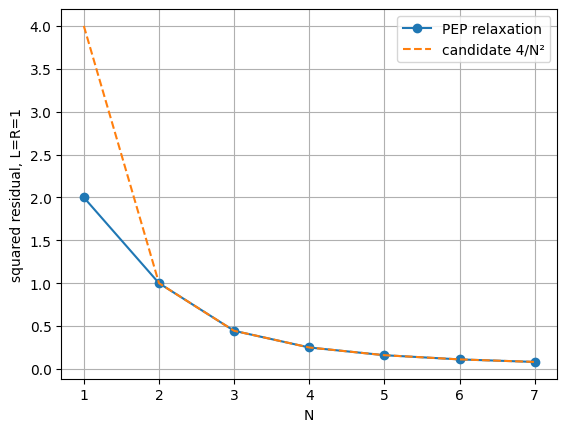

First-half alias and candidate-rate numerical checks passed.


In [5]:
evidence = json.loads((notebook_dir / "state/feg_b1.json").read_text())
rows = evidence["sweep_results"]
for row in rows:
    print(f"N={row['N']}: {row['opt_value']:.10f}; {row['status']}")
ns = [row["N"] for row in rows]
values = [row["opt_value"] for row in rows]
plt.plot(ns, values, "o-", label="PEP relaxation")
plt.plot(ns, [4 / n**2 for n in ns], "--", label="candidate 4/N²")
plt.xlabel("N")
plt.ylabel("squared residual, L=R=1")
plt.legend()
plt.grid(True)
plt.show()
assert all(row["first_half_same_point"] for row in rows)
assert max(abs(row["opt_value"] - 4 / row["N"] ** 2) for row in rows[1:]) < 1e-5
print("First-half alias and candidate-rate numerical checks passed.")

The conjectured bound is $\|A(x_N)\|^2\le 4L^2R^2/N^2$. It matches the relaxation for $N=2,\ldots,7$; the first-horizon value is $2L^2R^2$. Scaling follows from $x=Ry$ and $A(x)=LRB(y)$ for $R>0$; $R=0$ gives a stationary sequence. This was the B1 conjecture; the exact proof is now given above and verified below.

## Full-PEP certificate
The selected certificate is numerical and coherent at N=6, L=R=1. Analytic full-PEP and Lyapunov proofs remain unresolved.

In [6]:
import hashlib
import numpy as np
from pepflow.utils import Comparator

b2 = json.loads((notebook_dir / "state/feg_b2.json").read_text())
dense = json.loads((notebook_dir / "state/feg_dense.json").read_text())
for relative, expected in b2["certificate_provenance"]["source_hashes"].items():
    assert (
        hashlib.sha256((notebook_dir / relative).read_bytes()).hexdigest() == expected
    )
print("Dense objective:", dense["opt_value"])
print("Selected objective:", b2["opt_value"])
print("Basis:", b2["basis_vectors"])
for group in dense["lambda_groups"]:
    significant = [
        name
        for name, meta in dense["constraint_metadata"].items()
        if meta["group"] == group and abs(dense["named_dual_values"][name]) > 1e-6
    ]
    print(group, "significant entries:", len(significant))
print("Dense S eigenvalues:", np.linalg.eigvalsh(dense["S_matrix"]))
# The relaxation drops precisely the interpolation entries below the frozen cutoff.
dropped = [
    name
    for name, value in dense["named_dual_values"].items()
    if name != "initial_condition" and abs(value) <= 1e-6
]
assert dropped == b2["relaxed_constraints"]
assert abs(dense["opt_value"] - b2["opt_value"]) < 1e-5
assert abs(b2["opt_value"] - 4 / b2["N"] ** 2) < 1e-5
print("Dropped constraints:", len(dropped), "; objective preserved.")
for name, value in b2["named_dual_values"].items():
    if value is not None:
        print(name, value)

Dense objective: 0.11111111987991691
Selected objective: 0.11111111913421273
Basis: ['x_0', 'x_star', 'A(x_0)', 'A(x_1)', 'A(x_1+1/2)', 'A(x_2)', 'A(x_2+1/2)', 'A(x_3)', 'A(x_3+1/2)', 'A(x_4)', 'A(x_4+1/2)', 'A(x_5)', 'A(x_5+1/2)', 'A(x_6)']
Monotone Operator Inequality significant entries: 6
Lipschitz Continuous Inequality significant entries: 6
Dense S eigenvalues: [8.39304405e-11 3.12048790e-10 1.29506311e-09 1.48441766e-09
 3.74263384e-09 7.48946495e-09 1.01712929e-08 1.98970887e-08
 2.28208611e-08 2.54735437e-08 2.89888638e-08 3.77429491e-08
 5.92976464e-08 1.22214889e+00]
Dropped constraints: 144 ; objective preserved.
initial_condition 0.11111112569910349
A monotone:x_1,x_2 0.22227319498944406
A monotone:x_2,x_3 0.6668195130842369
A monotone:x_3,x_4 1.3336389582386639
A monotone:x_4,x_5 2.2227315150486944
A monotone:x_5,x_6 3.3340972127835244
A monotone:x_6,x_star 0.6668194526134993
A Lipschitz:x_0,x_1 0.05556830706343723
A Lipschitz:x_1+1/2,x_2 0.2222731844438772
A Lipschitz:x_

### Numerical decomposition and certificate identity
The saved reversed-basis LDL factors obey $S=E^\top D E$, with all factor entries retained. Scalar constraints are normalized as $r_i\le0$; the checked identity is
$$\mathrm{metric}-\mathrm{bound}-\sum_i\lambda_i r_i+S=0.$$
We check Gram, function-value and constant coordinates, inequality signs, positive semidefiniteness, and the dense/relaxed objective gap.

In [7]:
def verify_saved(data, dense_value):
    n = data["N_verify"]
    ctx, pb, obj = get_pep_setup(n, {"L": 1, "R": 1})
    ctx.set_as_current()
    pm = pf.ExpressionManager(ctx, resolve_parameters={"L": sp.S(1), "R": sp.S(1)})
    entries = [*pb.init_conditions, *obj.get_interpolation_constraints(ctx)]
    assert (
        set(c.name for c in entries)
        == set(data["named_dual_values"])
        == set(data["constraint_metadata"])
    )
    assert [str(v) for v in ctx.basis_vectors()] == data["basis_vectors"]
    assert [str(v) for v in ctx.basis_scalars()] == data["basis_scalars"]
    weighted = pf.Scalar.zero()
    active = []
    for c in entries:
        value = data["named_dual_values"][c.name]
        meta = data["constraint_metadata"][c.name]
        assert meta["comparator"] == c.cmp.value and meta["kind"] == "scalar"
        if meta["relaxed"]:
            assert value is None and c.name in data["relaxed_constraints"]
            continue
        assert value is not None and np.isfinite(value)
        residual = c.lhs - c.rhs
        if c.cmp in (Comparator.GE, Comparator.SEQ):
            residual = -residual
        weighted += value * residual
        if c.cmp != Comparator.EQ:
            active.append(value)
    basis = ctx.basis_vectors()
    S = np.asarray(data["S_matrix"], dtype=float)
    S_numeric = sum(
        (float(S[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S.shape)),
        pf.Scalar.zero(),
    )
    diff = pb.performance_metric - data["opt_value"] - weighted + S_numeric
    checked = pm.eval_scalar(diff)
    D = np.asarray(data["numerical_decomposition"]["D"])
    E = np.asarray(data["numerical_decomposition"]["ell_coords"])

    def max_abs(a):
        return float(np.max(np.abs(np.asarray(a, dtype=float)), initial=0.0))

    residuals = dict(
        identity_gram_max_abs=max_abs(checked.inner_prod_coords),
        identity_func_max_abs=max_abs(checked.func_coords),
        identity_offset_abs=max_abs(checked.offset),
        S_reconstruction_max_abs=max_abs(E.T @ D @ E - S),
        dense_relaxed_gap=abs(data["opt_value"] - dense_value),
        minimum_scalar_inequality_dual=min(active, default=0.0),
        minimum_S_eigenvalue=float(np.linalg.eigvalsh(S).min()),
        minimum_matrix_inequality_eigenvalue=0.0,
    )
    tolerances = dict(
        identity_atol=1e-5,
        identity_rtol=0,
        reconstruction_atol=1e-4,
        reconstruction_rtol=1e-5,
        dual_tol=1e-6,
        psd_tol=1e-6,
        dense_opt_atol=1e-5,
    )
    passed = (
        data["certificate_provenance"]["solver_status"] == "optimal"
        and all(
            residuals[k] <= 1e-5
            for k in [
                "identity_gram_max_abs",
                "identity_func_max_abs",
                "identity_offset_abs",
            ]
        )
        and np.allclose(S, S.T, atol=1e-6, rtol=0)
        and np.allclose(E.T @ D @ E, S, atol=1e-4, rtol=1e-5)
        and residuals["dense_relaxed_gap"] < 1e-5
        and residuals["minimum_scalar_inequality_dual"] >= -1e-6
        and residuals["minimum_S_eigenvalue"] >= -1e-6
    )
    assert passed, residuals
    return (
        ctx,
        pb,
        obj,
        pm,
        checked,
        dict(tolerances=tolerances, residuals=residuals, passed=bool(passed)),
    )

In [8]:
ctx_cert, pb_cert, A_cert, pm_cert, residual_cert, checks = verify_saved(
    b2, dense["opt_value"]
)
print(checks)
D = np.asarray(b2["numerical_decomposition"]["D"])
E = np.asarray(b2["numerical_decomposition"]["ell_coords"])
pf.pprint_labeled_matrix(
    E, [f"ell_{i}" for i in range(len(E))], b2["basis_vectors"], precision=5
)
print("LDL diagonal:", np.diag(D))
print("Off-diagonal LDL max:", np.max(np.abs(D - np.diag(np.diag(D)))))
pf.pprint_labeled_matrix(
    np.asarray(residual_cert.inner_prod_coords),
    b2["basis_vectors"],
    b2["basis_vectors"],
    precision=10,
)
print("Function residual:", residual_cert.func_coords, "offset:", residual_cert.offset)
pf.pprint_labeled_matrix(
    np.asarray(b2["S_matrix"]), b2["basis_vectors"], b2["basis_vectors"], precision=6
)

{'tolerances': {'identity_atol': 1e-05, 'identity_rtol': 0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05}, 'residuals': {'identity_gram_max_abs': 7.512999260122766e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 6.564890756011188e-09, 'S_reconstruction_max_abs': 5.551115123125783e-17, 'dense_relaxed_gap': 7.457041789615815e-10, 'minimum_scalar_inequality_dual': 0.05556830706343723, 'minimum_S_eigenvalue': 7.343470692425838e-10, 'minimum_matrix_inequality_eigenvalue': 0.0}, 'passed': True}

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r05\supplementary\approved\pepflow\pep_context.py:217: UserWarning:

The given tag x_0 was already associated with a Vector or Scalar in this PEPContext ctx_6. You can no longer access the old object by x_0.



<IPython.core.display.Math object>

LDL diagonal: [1.00045833e+00 7.51153006e-09 2.76501551e-08 7.48731479e-09
 3.51615286e-08 6.59481809e-09 2.70457645e-08 5.40293328e-09
 1.88429287e-08 4.96182345e-09 1.18374812e-08 2.26313258e-09
 9.84068699e-09 9.28986423e-09]
Off-diagonal LDL max: 0.0


<IPython.core.display.Math object>

Function residual: [] offset: 6.56489075601119e-9


<IPython.core.display.Math object>

### Initial closed-form search
The coefficient candidates at $L=R=1$ are $4k(k+1)/N^2$ for consecutive monotonicity ($1\le k<N$), $2(k+1)^2/N^2$ for half-step Lipschitz ($0\le k<N$), $4/N$ for terminal monotonicity, and $4/N^2$ for the initial condition. The proposed remainder is $\|(2/N)(x_0-x_\star)-A(x_N)\|^2$.
These plausible candidates do **not** match the selected numerical dual to the required $10^{-4}$ tolerance. They are recorded as unresolved guesses, not substituted for the saved certificate. The verified LDL decomposition supplies the numerical handoff.

In [9]:
n = b2["N"]
candidate = {"initial_condition": 4 / n**2, f"A monotone:x_{n},x_star": 4 / n}
for k in range(1, n):
    candidate[f"A monotone:x_{k},x_{k + 1}"] = 4 * k * (k + 1) / n**2
for k in range(n):
    half = "x_0" if k == 0 else f"x_{k}+1/2"
    candidate[f"A Lipschitz:{half},x_{k + 1}"] = 2 * (k + 1) ** 2 / n**2
lambda_error = max(
    abs(value - candidate.get(name, 0))
    for name, value in b2["named_dual_values"].items()
    if value is not None
)
v = 2 / n * (ctx_cert["x_0"] - ctx_cert["x_star"]) - A_cert(ctx_cert[f"x_{n}"])
S_guess = pm_cert.eval_scalar(v**2)
S_error = np.max(np.abs(S_guess.inner_prod_coords - np.asarray(b2["S_matrix"])))
pf.pprint_labeled_matrix(
    np.asarray(S_guess.inner_prod_coords),
    b2["basis_vectors"],
    b2["basis_vectors"],
    precision=5,
)
print("Lambda candidate error:", lambda_error)
print("S candidate error:", S_error)
print("Candidate S function/constant components:", S_guess.func_coords, S_guess.offset)
print("Numerical certificate verified:", checks["passed"])
print("Analytic full-PEP verified: False; Lyapunov proof verified: False")

<IPython.core.display.Math object>

Lambda candidate error: 0.0007638794501909629
S candidate error: 0.0004583265227982025
Candidate S function/constant components: [] 0.0
Numerical certificate verified: True
Analytic full-PEP verified: False; Lyapunov proof verified: False


### Additional certificate at N=8
The same consecutive monotonicity and half-step Lipschitz support is used. This separate coherent sample will support the required cross-horizon comparison; N=6 remains the selected handoff.

In [10]:
sample8 = json.loads(
    (notebook_dir / "supplementary/feg_certificate_N8.json").read_text()
)
dense8 = json.loads((notebook_dir / "supplementary/feg_dense_N8.json").read_text())
ctx8, pb8, A8, pm8, residual8, checks8 = verify_saved(sample8, dense8["opt_value"])
print("N=8 dense/relaxed objectives:", dense8["opt_value"], sample8["opt_value"])
print("N=8 complete certificate checks:", checks8)
print("Separate sample certificate ID:", sample8["certificate_id"])

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r05\supplementary\approved\pepflow\pep_context.py:217: UserWarning:

The given tag x_0 was already associated with a Vector or Scalar in this PEPContext ctx_8. You can no longer access the old object by x_0.



N=8 dense/relaxed objectives: 0.06250000276866949 0.06250000556044698
N=8 complete certificate checks: {'tolerances': {'identity_atol': 1e-05, 'identity_rtol': 0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05}, 'residuals': {'identity_gram_max_abs': 2.3087068836263637e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 3.094291448069164e-09, 'S_reconstruction_max_abs': 1.3877787807814457e-17, 'dense_relaxed_gap': 2.791777489741243e-09, 'minimum_scalar_inequality_dual': 0.03125669107477911, 'minimum_S_eigenvalue': 4.615231404822175e-11, 'minimum_matrix_inequality_eigenvalue': 0.0}, 'passed': True}
Separate sample certificate ID: e77ed56a5cd634001da6bd98608e6b1b6a6cad86729f729d4feff8288d16496f


## Lyapunov partial sums
With residuals $\operatorname{Mon}(u,v)=-\langle A(u)-A(v),u-v\rangle\le0$ and $\operatorname{Lip}(u,v)=\|A(u)-A(v)\|^2-L^2\|u-v\|^2\le0$, use $V_0=0$ and
$$V_{k+1}-V_k=\lambda_k^{\rm Lip}\operatorname{Lip}(x_{k+1/2},x_{k+1})+\lambda_k^{\rm Mon}\operatorname{Mon}(x_k,x_{k+1}),$$
where the monotonicity contribution is absent at $k=0$. Nonnegative numerical multipliers make these partial sums nonincreasing. Keep the terminal zero-point monotonicity and the complete positive semidefinite $S$ block for the boundary argument.
The same construction has interior rank 2 at $N=6$ and $N=8$, excluding exactly $V_0,V_N$ in both comparisons. All endpoints remain covered and saved. Ranks use unscaled absolute singular-value tolerance $10^{-4}$; the discarded singular values are far below the threshold.

In [11]:
KEYS = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)


def partial_sums(certificate, dense_value):
    digest = hashlib.sha256(
        json.dumps(
            {k: certificate[k] for k in KEYS},
            sort_keys=True,
            separators=(",", ":"),
            allow_nan=False,
        ).encode()
    ).hexdigest()
    assert digest == certificate["certificate_id"]
    assert certificate["closed_form_search"]["completed"]
    for relative, expected in certificate["certificate_provenance"][
        "source_hashes"
    ].items():
        assert (
            hashlib.sha256((runtime.ROOT / relative).read_bytes()).hexdigest()
            == expected
        )
    assert certificate["certificate_provenance"]["pep_type"] == "primal"
    assert certificate["params_json"] == '{"L": 1, "R": 1}'
    assert (
        certificate["normalization"]["tau_name"]
        == certificate["tau_name"]
        == "initial_condition"
    )
    assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
    assert (
        certificate["named_dual_values"]["initial_condition"] == certificate["tau_sol"]
    )
    ctx, pb, obj, pm, checked, numerical_checks = verify_saved(certificate, dense_value)
    n = certificate["N_verify"]
    basis = ctx.basis_vectors()
    assert (
        certificate["S_row_names"]
        == certificate["S_col_names"]
        == [str(v) for v in basis]
    )
    groups = ctx.get_constraint_data(obj)
    assert (
        not groups.psd_dict
        and not ctx.func_to_triplets
        and len(ctx.oper_to_duplets) == 1
    )
    terms = {}
    for group, constraints in groups.sc_dict.items():
        for c in constraints:
            expected = dict(
                origin="interpolation",
                owner=str(obj),
                group=group,
                kind="scalar",
                comparator=c.cmp.value,
                shape=[],
                relaxed=c.name in certificate["relaxed_constraints"],
            )
            assert certificate["constraint_metadata"][c.name] == expected
            value = certificate["named_dual_values"][c.name]
            if value is not None:
                assert c.cmp.value == "LE"
                terms[c.name] = value * (c.lhs - c.rhs)
    # A single PSD block retains every saved LDL component, including tiny terms.
    D = np.asarray(certificate["numerical_decomposition"]["D"])
    E = np.asarray(certificate["numerical_decomposition"]["ell_coords"])
    ell = [
        sum((float(coef) * v for coef, v in zip(row, basis)), pf.Vector.zero())
        for row in E
    ]
    S_block = sum(
        (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)),
        pf.Scalar.zero(),
    )
    S_matrix = np.asarray(certificate["S_matrix"])
    assert np.allclose(E.T @ D @ E, S_matrix, atol=1e-5, rtol=0)
    assert np.linalg.eigvalsh(S_matrix).min() >= -1e-6
    S_assignment = {"complete_S": "boundary"}
    assignment = {}
    for name in terms:
        if name == f"A monotone:x_{n},x_star":
            assignment[name] = "boundary"
        else:
            target = name.split(",")[1]
            assert target.startswith("x_") and target[2:].isdigit()
            assignment[name] = int(target[2:]) - 1
    assert sum(v == "boundary" for v in assignment.values()) == 1
    assert all(
        v == "boundary" or (isinstance(v, int) and 0 <= v < n)
        for v in assignment.values()
    )
    lyap = [pf.Scalar.zero()]
    partial_sum = pf.Scalar.zero()
    for step in range(n):
        partial_sum += sum(
            (terms[name] for name, target in assignment.items() if target == step),
            pf.Scalar.zero(),
        )
        lyap.append(partial_sum)
    values = [pm.eval_scalar(v) for v in lyap]
    singular_values = [
        np.linalg.svd(
            np.asarray(v.inner_prod_coords, dtype=float), compute_uv=False
        ).tolist()
        for v in values
    ]
    ranks = [int(np.sum(np.asarray(s) > 1e-4)) for s in singular_values]
    for k, rank in enumerate(ranks):
        print(f"rank V_{k}: {rank}")
        if k == 0:
            print()
    print(
        "Interior rank is constant at this N:",
        len(set(ranks[1:-1])) == 1 and n - 1 >= 3,
        "boundary exclusions:",
        (1, 1),
    )
    leftover = (
        sum(
            (
                terms[name]
                for name, target in assignment.items()
                if target == "boundary"
            ),
            pf.Scalar.zero(),
        )
        - S_block
    )
    coverage = lyap[n] + leftover - (sum(terms.values(), pf.Scalar.zero()) - S_block)
    residuals = []
    for expression in [
        coverage,
        S_block
        - sum(
            (
                float(S_matrix[i, j]) * basis[i] * basis[j]
                for i, j in np.ndindex(S_matrix.shape)
            ),
            pf.Scalar.zero(),
        ),
    ]:
        ev = pm.eval_scalar(expression)
        residuals.extend(
            float(np.max(np.abs(np.asarray(c, dtype=float)), initial=0))
            for c in [ev.inner_prod_coords, ev.func_coords, ev.offset]
        )
    for k in range(n):
        increment = sum(
            (terms[name] for name, target in assignment.items() if target == k),
            pf.Scalar.zero(),
        )
        ev = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
        residuals.extend(
            float(np.max(np.abs(np.asarray(c, dtype=float)), initial=0))
            for c in [ev.inner_prod_coords, ev.func_coords, ev.offset]
        )
    assert max(residuals) <= 1e-5
    # Every increment is a nonnegative linear combination of <=0 residuals.
    assert all(
        value >= -1e-6
        for name, value in certificate["named_dual_values"].items()
        if value is not None
    )
    observation = dict(
        N=n,
        certificate_id=certificate["certificate_id"],
        recipe_id="chronological_interpolation_complete_S_boundary",
        rank_profile=ranks,
        rank_convention=dict(
            tolerance=1e-4,
            scaling="unscaled absolute singular values",
            coordinate_order="setup basis order",
        ),
        rank_credible=all(
            not any(0.5e-4 < s < 2e-4 for s in ss) for ss in singular_values
        ),
        certificate_checked=True,
        grouping_checked=True,
        singular_values=singular_values,
        maximum_coverage_residual=max(residuals),
        numerical_checks=numerical_checks,
        constraint_assignment=assignment,
        S_assignment=S_assignment,
        boundary_constraints=[
            name for name, target in assignment.items() if target == "boundary"
        ],
        boundary_S=["complete_S"],
        omitted_constraints=[],
        sign_convention="V[k+1]-V[k] is a nonnegative combination of normalized <=0 interpolation residuals",
        lyap_inner_prod_coords=[
            np.asarray(v.inner_prod_coords, dtype=float).tolist() for v in values
        ],
        lyap_func_coords=[
            np.asarray(v.func_coords, dtype=float).tolist() for v in values
        ],
        lyap_offsets=[float(v.offset) for v in values],
    )
    return ctx, pb, obj, pm, lyap, observation


ctx_lyap, pb_lyap, A_lyap, pm_lyap, lyap, observation = partial_sums(
    b2, dense["opt_value"]
)

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r05\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



rank V_0: 0

rank V_1: 2
rank V_2: 2
rank V_3: 2
rank V_4: 2
rank V_5: 2
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)


In [12]:
import contextlib
import io

with contextlib.redirect_stdout(io.StringIO()):
    _, _, _, _, _, observation8 = partial_sums(sample8, dense8["opt_value"])
for obs in [observation, observation8]:
    assert (
        obs["certificate_checked"] and obs["grouping_checked"] and obs["rank_credible"]
    )
    assert len(obs["rank_profile"][1:-1]) >= 3
    assert set(obs["rank_profile"][1:-1]) == {2}
assert observation["recipe_id"] == observation8["recipe_id"]
assert observation["rank_convention"] == observation8["rank_convention"]
print(
    "Confirmed common interior rank: 2; horizons: 6,8; exclusions: (1,1); absolute tolerance: 1e-4."
)
print(
    "Full-coordinate coverage residuals:",
    observation["maximum_coverage_residual"],
    observation8["maximum_coverage_residual"],
)
print(
    "Boundary: one terminal monotonicity term and the complete PSD S block; no omitted terms."
)
print("Numerical certificate/grouping verified; analytic theorem remains pending.")

Confirmed common interior rank: 2; horizons: 6,8; exclusions: (1,1); absolute tolerance: 1e-4.
Full-coordinate coverage residuals: 1.1102230246251565e-16 1.8439029168146863e-16
Boundary: one terminal monotonicity term and the complete PSD S block; no omitted terms.
Numerical certificate/grouping verified; analytic theorem remains pending.


## Identify the vectors composing the Lyapunov function
Reconstruct the selected B3 certificate and its rank profile before scanning vectors. The cross-horizon rank evidence uses exclusions (1,1), but every index is reconstructed here.

In [13]:
import json
from itertools import combinations
import numpy as np
import pepflow as pf
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)
from partial_sums import partial_sums as replay_partial_sums  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.
from pepflow.utils import NUMERICAL_TYPE
import runtime  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.

b3 = json.loads((runtime.ROOT / "state/feg_b3.json").read_text())
dense = json.loads((runtime.ROOT / "state/feg_dense.json").read_text())
ctx, pb, obj, pm, lyap, observation = replay_partial_sums(b3, dense["opt_value"])
params_sp: dict[str, NUMERICAL_TYPE] = {"L": sp.S(1), "R": sp.S(1)}
n = b3["N_verify"]
rank_evidence = json.loads(
    (runtime.ROOT / b3["rank_search"]["evidence_path"]).read_text()
)
assert rank_evidence["summary"] == b3["rank_search"]
assert observation["rank_profile"] == b3["rank_profile"]
for key in ["lyap_inner_prod_coords", "lyap_func_coords", "lyap_offsets"]:
    assert np.allclose(
        np.asarray(observation[key]), np.asarray(b3[key]), atol=1e-5, rtol=0
    )

rank V_0: 0

rank V_1: 2
rank V_2: 2
rank V_3: 2
rank V_4: 2
rank V_5: 2
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)


### Candidate-vector scan
Scan operator values, tagged full and half iterates, basis vectors, anchor gaps, and their pairwise differences. Prefer the meaningful names g_k and q_k, and remove duplicate or zero coordinates.

In [14]:
candidate_pairs = []
for k in range(1, n + 1):
    candidate_pairs += [
        (f"g_{k}", obj(ctx[f"x_{k}"])),
        (f"q_{k}", ctx[f"x_{k}"] - ctx["x_0"]),
    ]
base = [(str(v), v) for v in ctx.basis_vectors()]
base += [(f"x_{k}", ctx[f"x_{k}"]) for k in range(n + 1)]
base += [(f"x_{k}+1/2", ctx[f"x_{k}+1/2"]) for k in range(1, n)]
candidate_pairs += base
candidate_pairs += [
    (f"({la})-({lb})", va - vb) for (la, va), (lb, vb) in combinations(base, 2)
]
unique_pairs = []
unique_coords = []
for label, v in candidate_pairs:
    coords = np.asarray(pm.eval_vector(v).coords, dtype=float)
    if np.linalg.norm(coords) <= 1e-6:
        continue
    if any(
        np.allclose(coords, c, atol=1e-7, rtol=0)
        or np.allclose(coords, -c, atol=1e-7, rtol=0)
        for c in unique_coords
    ):
        continue
    unique_pairs.append((label, v))
    unique_coords.append(coords)
candidates = [v for label, v in unique_pairs]
labels_by_id = {id(v): label for label, v in unique_pairs}
print("Distinct nonzero candidates:", len(candidates))

Distinct nonzero candidates: 323


In [15]:
in_column = {}
for k in range(1, n + 1):
    in_column[k] = vectors_in_column_space(
        lyap[k],
        candidates,
        pep_context=ctx,
        resolve_parameters=params_sp,
        rtol=1e-4,
        atol=1e-4,
    )
    print(f"V_{k} column-space candidates:")
    for v in in_column[k]:
        print("  ", labels_by_id[id(v)])

V_1 column-space candidates:
   g_1
   q_1
   (x_0)-(x_1+1/2)
   (A(x_0))-(A(x_1))
   (x_1)-(x_1+1/2)
V_2 column-space candidates:
   g_2
   q_2
   (x_0)-(x_2+1/2)
   (x_2)-(x_2+1/2)


V_3 column-space candidates:
   g_3
   q_3
   (x_0)-(x_3+1/2)
   (x_3)-(x_3+1/2)


V_4 column-space candidates:
   g_4
   q_4
   (x_0)-(x_4+1/2)
   (x_4)-(x_4+1/2)


V_5 column-space candidates:
   g_5
   q_5
   (x_0)-(x_5+1/2)
   (x_5)-(x_5+1/2)


V_6 column-space candidates:
   g_6
   q_6


### Selected basis pattern
The sparsity search below also finds diagonal coefficient bases using half-step differences. We adopt the full-iterate residual and anchor gap because the same template applies to the terminal index and directly describes the algorithm.

In [16]:
searched = {}
for k in range(1, n + 1):
    basis, C = find_basis_with_sparsest_coefficients(
        lyap[k],
        in_column[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        zero_tol=1e-6,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    assert len(basis) == b3["rank_profile"][k] == 2
    searched[k] = {"labels": [labels_by_id[id(v)] for v in basis], "C": C.tolist()}
    print(
        f"k={k}, rank 2; sparse basis: {searched[k]['labels']}; zero coefficients: {int(np.sum(np.abs(C) < 1e-6))}/{C.size}"
    )

k=1, rank 2; sparse basis: ['q_1', '(A(x_0))-(A(x_1))']; zero coefficients: 2/4
k=2, rank 2; sparse basis: ['q_2', '(x_2)-(x_2+1/2)']; zero coefficients: 2/4
k=3, rank 2; sparse basis: ['q_3', '(x_3)-(x_3+1/2)']; zero coefficients: 2/4


k=4, rank 2; sparse basis: ['q_4', '(x_4)-(x_4+1/2)']; zero coefficients: 2/4
k=5, rank 2; sparse basis: ['q_5', '(x_5)-(x_5+1/2)']; zero coefficients: 2/4
k=6, rank 2; sparse basis: ['g_6', 'q_6']; zero coefficients: 1/4


Use
$$g_k=A(x_k),\qquad q_k=x_k-x_0,\qquad \mathcal B_k=[g_k,q_k]\quad(1\le k\le N).$$
At $k=0$, $V_0=0$ and the quadratic basis is empty. The adopted basis is independently checked below.

In [17]:
# Adopt the same direct algorithmic basis at every noninitial index.
def V_k_basis(k):
    if k == 0:
        return []
    return [obj(ctx[f"x_{k}"]), ctx[f"x_{k}"] - ctx["x_0"]]


def V_k_basis_labels(k):
    return [] if k == 0 else [f"g_{k}", f"q_{k}"]


for k in range(n + 1):
    basis = V_k_basis(k)
    rank = (
        0
        if not basis
        else np.linalg.matrix_rank(
            np.column_stack([pm.eval_vector(v).coords for v in basis]).astype(float),
            tol=1e-7,
        )
    )
    assert rank == len(basis) == b3["rank_profile"][k]
    print(f"k={k}: rank {rank} basis {V_k_basis_labels(k)}")

k=0: rank 0 basis []
k=1: rank 2 basis ['g_1', 'q_1']
k=2: rank 2 basis ['g_2', 'q_2']
k=3: rank 2 basis ['g_3', 'q_3']
k=4: rank 2 basis ['g_4', 'q_4']
k=5: rank 2 basis ['g_5', 'q_5']
k=6: rank 2 basis ['g_6', 'q_6']


### Coefficient matrices
The basis order is [g_k,q_k] for all noninitial indices. Off-diagonal matrix entries contribute twice. There are no function-value or scalar-offset terms.

In [18]:
coeff_by_k = {}
quadratic_residuals = {}
component_residuals = {}
for k in range(n + 1):
    basis = V_k_basis(k)
    target = pm.eval_scalar(lyap[k])
    matrix = np.asarray(target.inner_prod_coords, dtype=float)
    if basis:
        C = find_symmetric_coefficient_matrix(
            lyap[k],
            basis,
            pep_context=ctx,
            resolve_parameters=params_sp,
            indep_tol=1e-7,
            span_tol=1e-5,
        )
        B = np.column_stack([pm.eval_vector(v).coords for v in basis]).astype(float)
        residual = float(np.linalg.norm(B @ C @ B.T - matrix, ord="fro"))
    else:
        C = np.zeros((0, 0))
        residual = float(np.linalg.norm(matrix, ord="fro"))
    assert residual <= 1e-5 * max(1.0, float(np.linalg.norm(matrix, ord="fro")))
    assert np.array_equal(C, C.T)
    assert (
        np.allclose(target.func_coords, 0, atol=1e-5, rtol=0)
        and abs(float(target.offset)) <= 1e-5
    )
    coeff_by_k[k] = C
    quadratic_residuals[str(k)] = residual
    print(
        f"k={k}: reconstruction residual {residual:.3g}; function terms {target.func_coords}; offset {target.offset}"
    )
    if basis:
        pf.pprint_labeled_matrix(
            C, V_k_basis_labels(k), V_k_basis_labels(k), precision=8
        )

k=0: reconstruction residual 0; function terms []; offset 0.0
k=1: reconstruction residual 1.96e-17; function terms []; offset 0


<IPython.core.display.Math object>

k=2: reconstruction residual 1.89e-08; function terms []; offset 0


<IPython.core.display.Math object>

k=3: reconstruction residual 2.58e-08; function terms []; offset 0


<IPython.core.display.Math object>

... (2 outputs left out)

k=5: reconstruction residual 4.98e-08; function terms []; offset 0


<IPython.core.display.Math object>

k=6: reconstruction residual 5.51e-08; function terms []; offset 0


<IPython.core.display.Math object>

In [19]:
def V_k_structure(k):
    vectors = V_k_basis(k)
    C = coeff_by_k[k]
    return sum(
        (float(C[i, j]) * vectors[i] * vectors[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )


for k in range(n + 1):
    difference = pm.eval_scalar(V_k_structure(k) - lyap[k])
    target = pm.eval_scalar(lyap[k])
    component_residuals[str(k)] = {}
    for name, coords, target_coords in [
        ("gram", difference.inner_prod_coords, target.inner_prod_coords),
        ("function", difference.func_coords, target.func_coords),
        ("offset", difference.offset, target.offset),
    ]:
        err = float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
        scale = float(np.max(np.abs(np.asarray(target_coords, dtype=float)), initial=0))
        assert err <= 1e-4 + 1e-5 * scale
        component_residuals[str(k)][name] = err
print("All indices 0..N independently reconstructed in every scalar component.")

All indices 0..N independently reconstructed in every scalar component.


### Block 4 conclusion
The verified numerical structure is
$$V_k=c_{gg}(k,N,L)\|g_k\|^2+2c_{gq}(k,N,L)\langle g_k,q_k\rangle+c_{qq}(k,N,L)\|q_k\|^2,$$
for $1\le k\le N$, with $V_0=0$. At the B4 handoff, all three exact coefficient functions were unknown; numerical coefficient matrices and full-coordinate checks cover every index. Block 5 derives their exact expressions and proves the step, base, and terminal identities. Numerical reconstruction is not an analytic convergence proof.

## Closed-form coefficient derivation
Start from the verified B4 basis and solve for all three quadratic coefficients and both local residual multipliers. The derivation uses a symbolic PEPFlow context with the actual two updates.

In [20]:
from typing import Any

b4_final = json.loads((runtime.ROOT / "state/feg_b4.json").read_text())
assert (
    b4_final["numerical_reconstruction"]["certificate_id"] == b4_final["certificate_id"]
)
assert b4_final["numerical_reconstruction"]["passed"]
proof_checks = {}

In [21]:
def exact_components(expression, manager):
    value = manager.eval_scalar(pf.Scalar.zero() + expression, sympy_mode=True)
    gram = sp.Matrix(value.inner_prod_coords).applyfunc(sp.factor)
    function = sp.Matrix(list(value.func_coords)).applyfunc(sp.factor)
    offset = sp.factor(sp.sympify(value.offset))
    return gram, function, offset


def exact_check(name, expression, manager):
    gram, function, offset = exact_components(expression, manager)
    labels = [str(v) for v in manager.context.basis_vectors()]
    pf.pprint_labeled_matrix(
        np.array(gram.tolist(), dtype=object), labels, labels, precision=0
    )
    print(name, "function residual:", function, "constant residual:", offset)
    assert all(value == 0 for value in [*gram, *function, offset]), name
    print(name, "all scalar components exactly zero.")
    return True

In [22]:
k_sym, N_sym = sp.symbols("k N", integer=True, positive=True)
L_sym = sp.Symbol("L", positive=True)
a_sym, b_sym, c_sym, ap_sym, bp_sym, cp_sym, u_sym, v_sym = sp.symbols(
    "a b c a_next b_next c_next u v", real=True
)
K = pf.Parameter("k_symbolic")
LL = pf.Parameter("L_symbolic")
NN = pf.Parameter("N_symbolic")
ctx_step = pf.PEPContext("feg_symbolic_step").set_as_current()
A_step = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{step}"], L=LL)
x_anchor = pf.Vector(is_basis=True, tags=["x_{0}"])
x_current = pf.Vector(is_basis=True, tags=["x_{k}"])
g_current = A_step(x_current)
x_half = x_current + (x_anchor - x_current) / (K + 1) - K / ((K + 1) * LL) * g_current
x_half.add_tag("x_{k+1/2}")
g_half = A_step(x_half)
x_next = x_current + (x_anchor - x_current) / (K + 1) - g_half / LL
x_next.add_tag("x_{k+1}")
g_next = A_step(x_next)
q_current = x_current - x_anchor
q_next = x_next - x_anchor
pa, pb_unknown, pc_unknown, pap, pbp, pcp, pu, pv = [
    pf.Parameter(name)
    for name in ["a", "b", "c", "a_next", "b_next", "c_next", "u", "v"]
]
P_current = (
    pa * g_current**2
    + 2 * pb_unknown * (g_current * q_current)
    + pc_unknown * q_current**2
)
P_next = pap * g_next**2 + 2 * pbp * (g_next * q_next) + pcp * q_next**2
I_lip = (g_next - g_half) ** 2 - LL**2 * (x_next - x_half) ** 2
I_mon = -(g_next - g_current) * (x_next - x_current)
unknown_map: dict[str, Any] = {
    "k_symbolic": k_sym,
    "L_symbolic": L_sym,
    "a": a_sym,
    "b": b_sym,
    "c": c_sym,
    "a_next": ap_sym,
    "b_next": bp_sym,
    "c_next": cp_sym,
    "u": u_sym,
    "v": v_sym,
}
manager_unknown = pf.ExpressionManager(ctx_step, resolve_parameters=unknown_map)
unknown_diff = P_next - P_current - pu * I_lip - pv * I_mon
G_unknown, F_unknown, o_unknown = exact_components(unknown_diff, manager_unknown)
equations = [entry for entry in [*G_unknown, *F_unknown, o_unknown] if entry != 0]
solutions = sp.solve(
    equations, [b_sym, c_sym, ap_sym, bp_sym, cp_sym, u_sym, v_sym], dict=True
)
assert len(solutions) == 1
solution = solutions[0]
print("Coefficient equations give:", solution)
expected = {
    b_sym: L_sym * a_sym / k_sym,
    c_sym: 0,
    ap_sym: a_sym * (k_sym + 1) ** 2 / k_sym**2,
    bp_sym: L_sym * a_sym * (k_sym + 1) / k_sym**2,
    cp_sym: 0,
    u_sym: a_sym * (k_sym + 1) ** 2 / k_sym**2,
    v_sym: 2 * L_sym * a_sym * (k_sym + 1) / k_sym,
}
assert all(sp.factor(solution[s] - expected[s]) == 0 for s in expected)
print("a_(k+1)/(k+1)^2 = a_k/k^2. Choose a_1=1: a_k=k^2, b_k=L*k, c_k=0.")
assert sp.simplify(((k_sym + 1) ** 2) / (k_sym + 1) ** 2 - k_sym**2 / k_sym**2) == 0

Coefficient equations give: {a_next: (a*k**2 + 2*a*k + a)/k**2, b: L*a/k, b_next: (L*a*k + L*a)/k**2, c: 0, c_next: 0, u: (a*k**2 + 2*a*k + a)/k**2, v: (2*L*a*k + 2*L*a)/k}


a_(k+1)/(k+1)^2 = a_k/k^2. Choose a_1=1: a_k=k^2, b_k=L*k, c_k=0.


The coefficient equations imply
$$c_{qq}(k)=0,\qquad c_{gq}(k)=\frac{L}{k}c_{gg}(k),\qquad
\frac{c_{gg}(k+1)}{(k+1)^2}=\frac{c_{gg}(k)}{k^2}.$$
Choose the free positive normalization $c_{gg}(1)=1$. Induction gives
$$C(k)=\begin{pmatrix}k^2&kL\\kL&0\end{pmatrix}.$$
The numerical certificate has a slightly different positive scale. The following comparison divides each numerical coefficient matrix by its first-step $c_{gg}$; no certificate entries are replaced.

In [23]:
sigma_sample = b4_final["coeff_by_k"]["1"][0][0]
assert sigma_sample > 0
for kk in range(1, b4_final["N_verify"] + 1):
    numerical_C = np.asarray(b4_final["coeff_by_k"][str(kk)]) / sigma_sample
    exact_C = np.array([[kk**2, kk], [kk, 0]], dtype=float)
    error = float(np.max(np.abs(numerical_C - exact_C)))
    print(
        "k=", kk, "coefficient comparison after positive scalar normalization:", error
    )
    assert np.allclose(numerical_C, exact_C, atol=1e-4, rtol=1e-5)
    pf.pprint_labeled_matrix(
        exact_C, [f"g_{kk}", f"q_{kk}"], [f"g_{kk}", f"q_{kk}"], precision=0
    )
print(
    "The final potential U is normalized by a_1=1; the numerical partial sums have a positive solver-dependent scale."
)

k= 1 coefficient comparison after positive scalar normalization: 2.220446049250313e-16


<IPython.core.display.Math object>

k= 2 coefficient comparison after positive scalar normalization: 7.883967327870778e-07


<IPython.core.display.Math object>

k= 3 coefficient comparison after positive scalar normalization: 2.4010739885227395e-06


<IPython.core.display.Math object>

... (3 outputs left out)

<IPython.core.display.Math object>

k= 6 coefficient comparison after positive scalar normalization: 1.3122431504086762e-05


<IPython.core.display.Math object>

The final potential U is normalized by a_1=1; the numerical partial sums have a positive solver-dependent scale.


### Closed-form Lyapunov conclusion
The exact potential is
$$V_{0}=0,\qquad V_{k}=k^2\|A(x_{k})\|^2+2kL\langle A(x_{k}),x_{k}-x_{0}\rangle\quad(1\le k\le N).$$
There are no function-value or offset terms. We next verify the decrease, initial step, and terminal normalization symbolically, over the complete stated domain.

## Symbolic Step Recursion Verification

For $1\le k<N$ and $L>0$, verify
$$V_{k+1}-V_{k}=(k+1)^2\operatorname{Lip}(x_{k+1/2},x_{k+1})+2k(k+1)L\operatorname{Mon}(x_{k},x_{k+1}).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero in every scalar component.

In [24]:
ctx_step.set_as_current()
step_LHS = (
    (K + 1) ** 2 * g_next**2
    + 2 * (K + 1) * LL * (g_next * q_next)
    - (K**2 * g_current**2 + 2 * K * LL * (g_current * q_current))
)
step_RHS = (K + 1) ** 2 * I_lip + 2 * K * (K + 1) * LL * I_mon
step_diff = step_LHS - step_RHS
step_map: dict[str, Any] = {"k_symbolic": k_sym, "L_symbolic": L_sym}
manager_step = pf.ExpressionManager(ctx_step, resolve_parameters=step_map)
proof_checks["step"] = exact_check("Step", step_diff, manager_step)

<IPython.core.display.Math object>

Step function residual: Matrix(0, 0, []) constant residual: 0
Step all scalar components exactly zero.


## Base Case and Boundary Symbolic Verification

With $x_{1/2}=x_{0}$ and $x_{1}=x_{0}-A(x_{0})/L$, verify
$$V_{1}-V_{0}=\operatorname{Lip}(x_{0},x_{1}),\qquad V_{0}=0.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero. Lipschitz continuity then yields $V_{1}\le0$.

In [25]:
ctx_base = pf.PEPContext("feg_symbolic_base").set_as_current()
A_base = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{base}"], L=LL)
x_initial = pf.Vector(is_basis=True, tags=["x_{0}"])
x_initial.add_tag("x_{1/2}")
g_initial = A_base(x_initial)
x_first = x_initial - g_initial / LL
x_first.add_tag("x_{1}")
g_first = A_base(x_first)
base_LHS = g_first**2 + 2 * LL * (g_first * (x_first - x_initial))
base_RHS = (g_first - g_initial) ** 2 - LL**2 * (x_first - x_initial) ** 2
base_diff = base_LHS - base_RHS
base_map: dict[str, Any] = {"L_symbolic": L_sym}
manager_base = pf.ExpressionManager(ctx_base, resolve_parameters=base_map)
proof_checks["base"] = exact_check("Base U_1-U_0=Lip(x_0,x_1)", base_diff, manager_base)

<IPython.core.display.Math object>

Base U_1-U_0=Lip(x_0,x_1) function residual: Matrix(0, 0, []) constant residual: 0
Base U_1-U_0=Lip(x_0,x_1) all scalar components exactly zero.


### Boundary Identity Symbolic Verification

For $N\ge1$, $L>0$, $d=x_{0}-x_{\star}$ and $A(x_{\star})=0$, verify
$$N^2\|A(x_{N})\|^2-4L^2\|d\|^2
=2V_{N}+4NL\operatorname{Mon}(x_{N},x_{\star})-\|NA(x_{N})-2Ld\|^2.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero in every scalar component.

In [26]:
ctx_boundary = pf.PEPContext("feg_symbolic_boundary").set_as_current()
A_boundary = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{boundary}"], L=LL)
x_start = pf.Vector(is_basis=True, tags=["x_{0}"])
x_terminal = pf.Vector(is_basis=True, tags=["x_{N}"])
x_zero = A_boundary.set_zero_point("x_{star}")
g_terminal = A_boundary(x_terminal)
d_initial = x_start - x_zero
U_terminal = NN**2 * g_terminal**2 + 2 * NN * LL * (g_terminal * (x_terminal - x_start))
I_terminal = -(g_terminal * (x_terminal - x_zero))
terminal_square = (NN * g_terminal - 2 * LL * d_initial) ** 2
boundary_LHS = NN**2 * g_terminal**2 - 4 * LL**2 * d_initial**2
boundary_RHS = 2 * U_terminal + 4 * NN * LL * I_terminal - terminal_square
boundary_diff = boundary_LHS - boundary_RHS
boundary_map: dict[str, Any] = {"N_symbolic": N_sym, "L_symbolic": L_sym}
manager_boundary = pf.ExpressionManager(ctx_boundary, resolve_parameters=boundary_map)
proof_checks["boundary"] = exact_check("Boundary", boundary_diff, manager_boundary)

<IPython.core.display.Math object>

Boundary function residual: Matrix(0, 0, []) constant residual: 0
Boundary all scalar components exactly zero.


### Signs, domain, and normalization
For integer $k\ge1$, $N\ge1$ and $L>0$, the multipliers $(k+1)^2$, $2k(k+1)L$, and $4NL$ are positive. The square norm is nonnegative. All divisions use only $k$, $k+1$, $N$ or $L$, which are nonzero on their respective domains. Monotonicity, Lipschitz continuity, and $V_{N}\le0$ therefore make the terminal right-hand side nonpositive. Using $\|x_{0}-x_{\star}\|^2\le R^2$ proves the stated rate. No additional condition on $R\ge0$ is needed.

In [27]:
assert ((k_sym + 1) ** 2).is_positive
assert (2 * k_sym * (k_sym + 1) * L_sym).is_positive
assert (4 * N_sym * L_sym).is_positive
assert (N_sym**2).is_positive
proof_checks["signs"] = True
proof_checks["domain"] = True
proof_checks["normalization"] = True
print(
    "For integer k>=1, N>=1 and L>0, all residual multipliers are nonnegative and denominators are nonzero."
)
print(
    "U_1<=0, U_(k+1)<=U_k, and terminal RHS<=0; hence N^2 ||A(x_N)||^2 <= 4 L^2 ||x_0-x_star||^2 <= 4 L^2 R^2."
)
print("N=1 uses only base and boundary; R=0 is covered without dividing by R.")
assert all(proof_checks.values())

For integer k>=1, N>=1 and L>0, all residual multipliers are nonnegative and denominators are nonzero.
U_1<=0, U_(k+1)<=U_k, and terminal RHS<=0; hence N^2 ||A(x_N)||^2 <= 4 L^2 ||x_0-x_star||^2 <= 4 L^2 R^2.
N=1 uses only base and boundary; R=0 is covered without dividing by R.


In [28]:
print("V_k = k^2 ||A(x_k)||^2 + 2 k L <A(x_k), x_k-x_0>; V_0=0")
print(r"\|A(x_N)\|^2 \le \frac{4L^2R^2}{N^2},\qquad N\ge1.")
print(
    "Numerical certificate verified: True; analytic full-PEP formula verified: False; analytic Lyapunov proof verified:",
    all(proof_checks.values()),
)

V_k = k^2 ||A(x_k)||^2 + 2 k L <A(x_k), x_k-x_0>; V_0=0
\|A(x_N)\|^2 \le \frac{4L^2R^2}{N^2},\qquad N\ge1.
Numerical certificate verified: True; analytic full-PEP formula verified: False; analytic Lyapunov proof verified: True
